In [2]:
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.model_selection import train_test_split, RandomizedSearchCV
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import r2_score, mean_absolute_error
import seaborn as sns
import matplotlib.pyplot as plt
import warnings
warnings.filterwarnings("ignore")

np.bool = bool
# 文件路径
btc_file = r"D:\桌面\绿色货币\Data\Historical Bitcoin greenhouse gas emissions.csv"
sp500_file = r"D:\桌面\绿色货币\Data\S&P 500 Historical Data.csv"
csi300_file = r"D:\桌面\绿色货币\Data\Shanghai Shenzhen CSI 300 Historical Data.csv"
ftse_germany_file = r"D:\桌面\绿色货币\Data\FTSE Germany Historical Data.csv"
etf_1653_file = r"D:\桌面\绿色货币\Data\1653 ETF Stock Price History.csv"
brent_oil_file = r"D:\桌面\绿色货币\Data\Brent Oil Futures Historical Data.csv"
btc_usd_file = r"D:\桌面\绿色货币\Data\BTC_USD Bitfinex Historical Data.csv"
gold_futures_file = r"D:\桌面\绿色货币\Data\Gold Futures Historical Data.csv"
etf_lywat_file = r"D:\桌面\绿色货币\Data\LYWAT ETF Stock Price History.csv"
etf_nubd_file = r"D:\桌面\绿色货币\Data\NUBD ETF Stock Price History 2018 bond.csv"

# 读取文件
btc_usd_df = pd.read_csv(btc_usd_file)
btc_df = pd.read_csv(btc_file)
sp500_df = pd.read_csv(sp500_file)
csi300_df = pd.read_csv(csi300_file)
ftse_germany_df = pd.read_csv(ftse_germany_file)
etf_1653_df = pd.read_csv(etf_1653_file)
brent_oil_df = pd.read_csv(brent_oil_file)
gold_futures_df = pd.read_csv(gold_futures_file)
etf_lywat_df = pd.read_csv(etf_lywat_file)
etf_nubd_df = pd.read_csv(etf_nubd_file)

# 统一日期格式
btc_usd_df["Date"] = pd.to_datetime(btc_usd_df["Date"], format="%m/%d/%Y").dt.strftime("%Y-%m-%d")
btc_df["Date"] = pd.to_datetime(btc_df["Date"], format="%Y/%m/%d").dt.strftime("%Y-%m-%d")
sp500_df["Date"] = pd.to_datetime(sp500_df["Date"], format="%m/%d/%Y").dt.strftime("%Y-%m-%d")
csi300_df["Date"] = pd.to_datetime(csi300_df["Date"], format="%m/%d/%Y").dt.strftime("%Y-%m-%d")
ftse_germany_df["Date"] = pd.to_datetime(ftse_germany_df["Date"], format="%m/%d/%Y").dt.strftime("%Y-%m-%d")
etf_1653_df["Date"] = pd.to_datetime(etf_1653_df["Date"], format="%m/%d/%Y").dt.strftime("%Y-%m-%d")
brent_oil_df["Date"] = pd.to_datetime(brent_oil_df["Date"], format="%m/%d/%Y").dt.strftime("%Y-%m-%d")
gold_futures_df["Date"] = pd.to_datetime(gold_futures_df["Date"], format="%m/%d/%Y").dt.strftime("%Y-%m-%d")
etf_lywat_df["Date"] = pd.to_datetime(etf_lywat_df["Date"], format="%m/%d/%Y").dt.strftime("%Y-%m-%d")
etf_nubd_df["Date"] = pd.to_datetime(etf_nubd_df["Date"], format="%m/%d/%Y").dt.strftime("%Y-%m-%d")

# 只保留 Price 列并重命名
btc_usd_df = btc_usd_df[["Date", "Price"]].rename(columns={"Price": "BTC/USD Price"})
sp500_df = sp500_df[["Date", "Price"]].rename(columns={"Price": "S&P 500 Price"})
csi300_df = csi300_df[["Date", "Price"]].rename(columns={"Price": "CSI 300 Price"})
ftse_germany_df = ftse_germany_df[["Date", "Price"]].rename(columns={"Price": "FTSE Germany Price"})
etf_1653_df = etf_1653_df[["Date", "Price"]].rename(columns={"Price": "1653 ETF Price"})
brent_oil_df = brent_oil_df[["Date", "Price"]].rename(columns={"Price": "Brent Oil Price"})
gold_futures_df = gold_futures_df[["Date", "Price"]].rename(columns={"Price": "Gold Futures Price"})
etf_lywat_df = etf_lywat_df[["Date", "Price"]].rename(columns={"Price": "LYWAT ETF Price"})
etf_nubd_df = etf_nubd_df[["Date", "Price"]].rename(columns={"Price": "NUBD ETF Price"})

# 以 BTC/USD 数据为基准合并数据
merged_df = (
    btc_usd_df
    .merge(btc_df, on="Date", how="left")
    .merge(sp500_df, on="Date", how="left")
    .merge(csi300_df, on="Date", how="left")
    .merge(ftse_germany_df, on="Date", how="left")
    .merge(etf_1653_df, on="Date", how="left")
    .merge(brent_oil_df, on="Date", how="left")
    .merge(gold_futures_df, on="Date", how="left")
    .merge(etf_lywat_df, on="Date", how="left")
    .merge(etf_nubd_df, on="Date", how="left")
)

for col in merged_df.select_dtypes(include=['object']).columns:
    if col != 'close':  # 如果 'close' 已经转换，则跳过
        try:
            merged_df[col] = merged_df[col].str.replace(',', '')
            merged_df[col] = pd.to_numeric(merged_df[col])
        except Exception as e:
            print(f"列 {col} 转换失败，保留原类型。错误信息：{e}")
merged_df

merged_df = merged_df.dropna()
merged_df.tail()
merged_df.to_csv('merged_data.csv',index=False)

列 Date 转换失败，保留原类型。错误信息：Unable to parse string "2015-01-01" at position 0


In [16]:
data = merged_df.copy()

# 转换 Date 列为 dateDate 格式
data["Date"] = pd.to_datetime(data["Date"], errors='coerce')

# 提取日期中的 day 信息
data["day"] = data["Date"].dt.day

# 对 day 列做周期性编码（使用 31 天为周期）
data["day_sin"] = np.sin(2 * np.pi * data["day"] / 31)
data["day_cos"] = np.cos(2 * np.pi * data["day"] / 31)

data = data.drop(columns=["Date","day"])

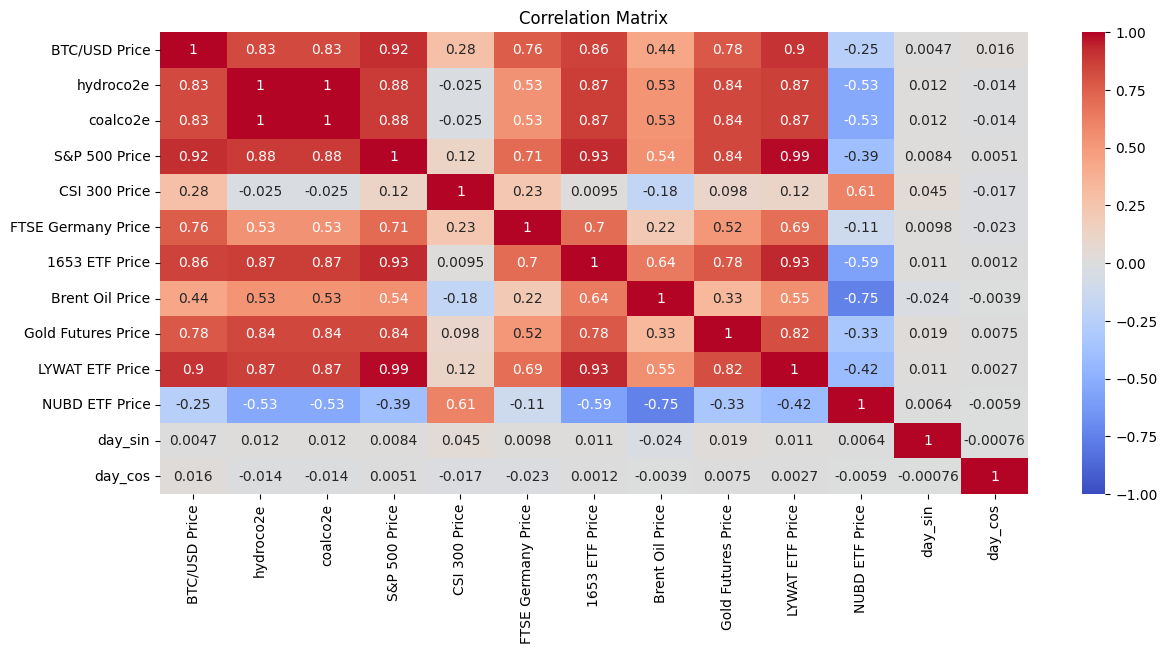

In [21]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns  # 需要导入 Seaborn

# 计算 Spearman 相关性矩阵
corr_matrix = data.corr(method='spearman')

# 使用 Seaborn 绘制热图
plt.figure(figsize=(14, 6))
sns.heatmap(corr_matrix, annot=True, cmap='coolwarm', vmin=-1, vmax=1)
plt.title('Correlation Matrix')

# 保存为 PDF
pdf_path = "corr_matrix.pdf"  # 指定 PDF 文件名
plt.savefig(pdf_path, format="pdf", bbox_inches='tight')  # bbox_inches='tight' 以确保完整保存
plt.show()  # 关闭图像，避免干扰后续绘图


In [18]:
target_col = "BTC/USD Price"


X = data.drop(columns=[target_col])
y = data[target_col]

# 拆分训练集和测试集（测试集占 20%）
x_train, x_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42)

# 4️⃣ 定义基本的随机森林模型与超参数搜索空间
rf_base = RandomForestRegressor(random_state=42, n_jobs=6)  # 使用 6 核进行训练

# 为避免模型配置问题，这里暂时只使用少量参数组合
param_grid = {
    "n_estimators": [10,50,100, 200],
    "max_depth": [3,5,10, None],
    "min_samples_split": [2, 5],
    "min_samples_leaf": [1, 2],
    "max_features": ["sqrt"],
    "bootstrap": [True]
}

# 5️⃣ 使用 RandomizedSearchCV 进行超参数随机搜索
random_search = RandomizedSearchCV(
    estimator=rf_base,
    param_distributions=param_grid,
    n_iter=5,              # 此处试验 2 组参数组合
    scoring="r2",
    cv=3,                   # 3 折交叉验证
    verbose=2,
    random_state=42,
    n_jobs=6,               # 并行使用 6 个 CPU 核心
    error_score='raise'
)

print("\n🎯 Running Random Search with 6 CPU Cores...")
random_search.fit(x_train, y_train)

# 输出随机搜索得到的最佳超参数
best_params = random_search.best_params_
print("\n✅ Best Parameters (Random Search):", best_params)

# 6️⃣ 使用最佳超参数在完整训练集上训练模型
best_rf = RandomForestRegressor(**best_params, random_state=42, n_jobs=6)
best_rf.fit(x_train, y_train)

# 在测试集上进行预测并评估模型性能
y_pred = best_rf.predict(x_test)
r2 = r2_score(y_test, y_pred)
mae = mean_absolute_error(y_test, y_pred)

print("\n📌 **Final Model Performance:**")
print(f"   - R² Score: {r2:.4f}")
print(f"   - Mean Absolute Error: {mae:.4f}")


🎯 Running Random Search with 6 CPU Cores...
Fitting 3 folds for each of 5 candidates, totalling 15 fits

✅ Best Parameters (Random Search): {'n_estimators': 100, 'min_samples_split': 2, 'min_samples_leaf': 2, 'max_features': 'sqrt', 'max_depth': None, 'bootstrap': True}

📌 **Final Model Performance:**
   - R² Score: 0.9828
   - Mean Absolute Error: 1694.6160


               feature  importance
11             day_cos    0.000956
10             day_sin    0.001144
6      Brent Oil Price    0.010901
3        CSI 300 Price    0.027417
9       NUBD ETF Price    0.033201
7   Gold Futures Price    0.050628
0            hydroco2e    0.061007
1             coalco2e    0.117383
5       1653 ETF Price    0.122886
8      LYWAT ETF Price    0.166562
2        S&P 500 Price    0.202428
4   FTSE Germany Price    0.205486


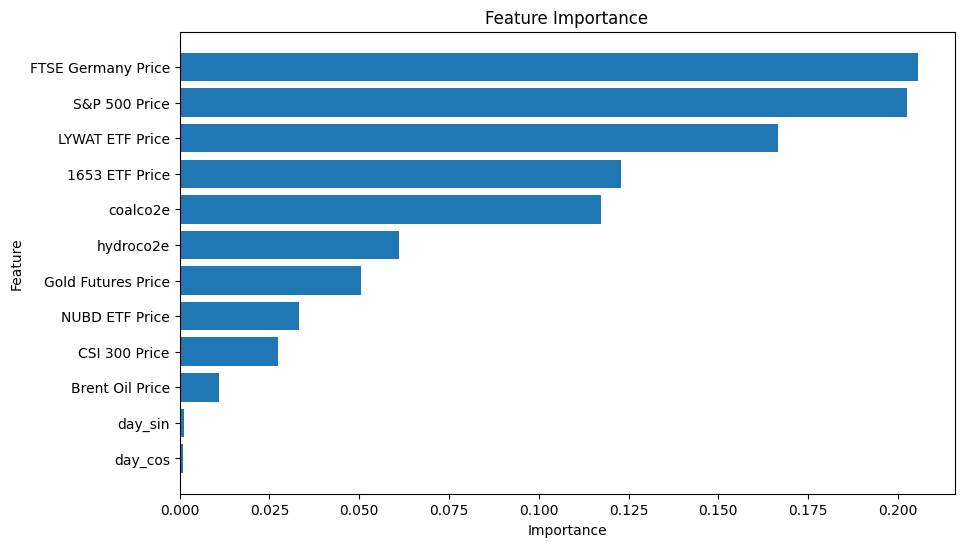

In [19]:
import pandas as pd
import matplotlib.pyplot as plt

# 获取特征重要性
importances = best_rf.feature_importances_
features = x_train.columns

# 将特征重要性转换为 DataFrame 并排序
importance_df = pd.DataFrame({'feature': features, 'importance': importances})
importance_df = importance_df.sort_values('importance', ascending=True)  # 由小到大排序，以便更好展示
print(importance_df )
# 画特征重要性水平条形图
plt.figure(figsize=(10, 6))
plt.barh(importance_df['feature'], importance_df['importance'])
plt.xlabel("Importance")
plt.ylabel("Feature")
plt.title("Feature Importance")

# 保存为 PDF
pdf_path = "feature_importance.pdf"  # 可修改路径
plt.savefig(pdf_path, format="pdf", bbox_inches='tight')
plt.show()  # 关闭图像，防止干扰后续绘图


DID

In [ ]:
data[target_col]